# Задача 6. Затухание

Для пройденного фотоном расстояния $d$ вероятность выживания
при длине затухания $L=8$ м равна

$$P_{\rm surv}(d)=\exp(-d/L).$$

Геометрическое попадание и поглощение разыгрываются для каждого
луча векторизованно. Для каждой координаты источника сначала
оценивается полная вероятность регистрации, затем строится
ансамбль зарядов с пуассоновским числом исходных фотонов.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from src.model import (
    Detector, Source, simulate_charge_ensemble_poisson,
)

detector = Detector(R=2.0, N=40, r=0.10, a=0.5)
z_values = np.linspace(-1.5, 1.5, 7)
attenuation_length = 8.0
p_clear, p_attenuated = [], []

for index, z in enumerate(z_values):
    position = np.array([0.0, 0.0, z])
    p0, _ = detector.estimate_detection_probability(
        position, 120_000, np.random.default_rng(6000 + index)
    )
    p8, _ = detector.estimate_detection_probability(
        position, 120_000, np.random.default_rng(6100 + index),
        attenuation_length=attenuation_length,
    )
    p_clear.append(p0)
    p_attenuated.append(p8)

p_clear = np.asarray(p_clear)
p_attenuated = np.asarray(p_attenuated)
print(" z, м       P без затухания       P при L=8 м")
for z, p0, p8 in zip(z_values, p_clear, p_attenuated):
    print(f"{z:+5.2f}          {p0:.6f}            {p8:.6f}")

 z, м       P без затухания       P при L=8 м
-1.50          0.024567            0.020375
-1.00          0.025258            0.020250
-0.50          0.025450            0.019125
+0.00          0.024375            0.019075
+0.50          0.025358            0.019617
+1.00          0.024833            0.020708
+1.50          0.024633            0.019850


In [2]:
n_events = 3000
mean_clear, mean_attenuated = [], []
distributions = {}
for index, z in enumerate(z_values):
    source = Source(Y=10_000.0, position=np.array([0.0, 0.0, z]))
    _, q0 = simulate_charge_ensemble_poisson(
        detector, source, 1.0, n_events, p_clear[index],
        np.random.default_rng(6200 + index),
    )
    _, q8 = simulate_charge_ensemble_poisson(
        detector, source, 1.0, n_events, p_attenuated[index],
        np.random.default_rng(6300 + index),
    )
    mean_clear.append(q0.mean())
    mean_attenuated.append(q8.mean())
    distributions[z] = (q0, q8)

mean_clear = np.asarray(mean_clear)
mean_attenuated = np.asarray(mean_attenuated)

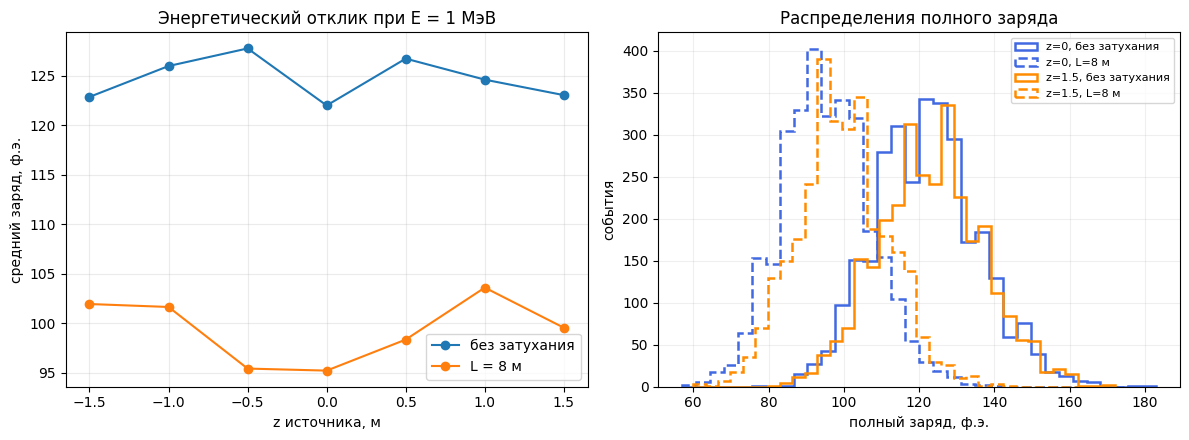

Снижение среднего заряда, %: [17.04 19.33 25.33 21.97 22.41 16.87 19.11]


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(z_values, mean_clear, "o-", label="без затухания")
axes[0].plot(z_values, mean_attenuated, "o-", label="L = 8 м")
axes[0].set(xlabel="z источника, м", ylabel="средний заряд, ф.э.",
            title="Энергетический отклик при E = 1 МэВ")
axes[0].legend()
axes[0].grid(alpha=0.25)

for z, color in [(0.0, "royalblue"), (1.5, "darkorange")]:
    q0, q8 = distributions[z]
    bins = np.linspace(min(q0.min(), q8.min()), max(q0.max(), q8.max()), 35)
    axes[1].hist(q0, bins=bins, histtype="step", linewidth=1.8,
                 color=color, label=f"z={z:g}, без затухания")
    axes[1].hist(q8, bins=bins, histtype="step", linestyle="--",
                 linewidth=1.8, color=color, label=f"z={z:g}, L=8 м")
axes[1].set(xlabel="полный заряд, ф.э.", ylabel="события",
            title="Распределения полного заряда")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.2)
plt.tight_layout()
fig.savefig("figures/task6_attenuation_response.png", dpi=180, bbox_inches="tight")
plt.show()

reduction = 100 * (1 - mean_attenuated / mean_clear)
print("Снижение среднего заряда, %:", np.round(reduction, 2))

**Вывод.** Затухание сдвигает распределения заряда влево.
Эффект зависит от положения источника, потому что меняется
распределение длин оптических путей до фотокатодов.